### Imported libraries and load data 

In [1]:
import pandas as pd

In [2]:
import pandas as pd
print(pd.__version__)

3.0.5


In [3]:
print("Jupyter is working!")

Jupyter is working!


In [5]:
import numpy as np
import matplotlib.pyplot as plt

In [6]:
import numpy as np
print("NumPy:", np.__version__)

NumPy: 2.2.5


In [7]:
sales = pd.read_csv("../Data/raw/m5-forecasting-accuracy/sales_train_validation.csv")
calendar= pd.read_csv("../Data/raw/m5-forecasting-accuracy/calendar.csv")
Prices= pd.read_csv("../Data/raw/m5-forecasting-accuracy/sell_prices.csv")

In [8]:
print("Sales:", sales.shape)
print("Calendar:", calendar.shape)
print("Prices:", Prices.shape)

Sales: (30490, 1919)
Calendar: (1969, 14)
Prices: (6841121, 4)


In [9]:
sales.describe()

,d_1,d_2,d_3,d_4,d_5,d_6,d_7,d_8,d_9,d_10,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
count,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,...,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000
mean,1.070220,1.041292,0.780026,0.833454,0.627944,0.958052,0.918662,1.244080,1.073663,0.838701,...,1.370581,1.586159,1.693670,1.248245,1.232207,1.159167,1.149000,1.328862,1.605838,1.633158
std,5.126689,5.365468,3.667454,4.415141,3.379344,4.785947,5.059495,6.617729,5.917204,4.206199,...,3.740017,4.097191,4.359809,3.276925,3.125471,2.876026,2.950364,3.358012,4.089422,3.812248
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,2.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,2.000000
max,360.000000,436.000000,207.000000,323.000000,296.000000,314.000000,316.000000,370.000000,385.000000,353.000000,...,129.000000,160.000000,204.000000,98.000000,100.000000,88.000000,77.000000,141.000000,171.000000,130.000000


### Convert sales data into a time-series format

#### Converted the sales dataset from wide format to long format using melt().

In [10]:
sales_columns = [
    col for col in sales.columns
    if col.startswith("d_")
]

sales_long = sales.melt(  # melt() converts columns into rows.
    id_vars=[             #columns we want to keep unchanged.
        "id",
        "item_id",
        "dept_id",
        "cat_id",
        "store_id",
        "state_id"
    ],
    value_vars=sales_columns, 
    var_name="d",            # name of the new column containing the original column names.
    value_name="sales"      #name of the new column containing their values.
)

sales_long.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0


In [11]:
print(f"Sales dataset memory: {sales.memory_usage(deep=True).sum() / 1024**2:.2f} MB") # Just checking up my pc memory for the further taks 

Sales dataset memory: 448.23 MB


In [31]:
import psutil

ram = psutil.virtual_memory()

print(f"Total RAM: {ram.total / 1024**3:.2f} GB")
print(f"Available RAM: {ram.available / 1024**3:.2f} GB")

Total RAM: 15.70 GB
Available RAM: 2.72 GB


In [18]:
print(f"Sales memory: {sales.memory_usage(deep=True).sum() / 1024**3:.2f} GB")

Sales memory: 0.44 GB


In [19]:
print("Shape:", sales_long.shape)
print(
    f"Memory usage: "
    f"{sales_long.memory_usage(deep=True).sum() / 1024**3:.2f} GB"
)

Shape: (58327370, 8)
Memory usage: 7.20 GB


In [20]:
sales_long.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0


In [21]:
sales_long.info()

<class 'pandas.DataFrame'>
RangeIndex: 58327370 entries, 0 to 58327369
Data columns (total 8 columns):
 #   Column    Dtype
---  ------    -----
 0   id        str  
 1   item_id   str  
 2   dept_id   str  
 3   cat_id    str  
 4   store_id  str  
 5   state_id  str  
 6   d         str  
 7   sales     int64
dtypes: int64(1), str(7)
memory usage: 7.2 GB


### Merging calendar data on sales 

In [22]:
sales_long = sales_long.merge(
    calendar[["d", "date", "weekday", "event_name_1", "event_type_1"]],
    on="d",
    how="left"
)

In [23]:
sales_long[["item_id", "store_id", "d", "date", "sales", "weekday"]].head(10)

,item_id,store_id,d,date,sales,weekday
0,HOBBIES_1_001,CA_1,d_1,2011-01-29,0,Saturday
1,HOBBIES_1_002,CA_1,d_1,2011-01-29,0,Saturday
2,HOBBIES_1_003,CA_1,d_1,2011-01-29,0,Saturday
3,HOBBIES_1_004,CA_1,d_1,2011-01-29,0,Saturday
4,HOBBIES_1_005,CA_1,d_1,2011-01-29,0,Saturday
5,HOBBIES_1_006,CA_1,d_1,2011-01-29,0,Saturday
6,HOBBIES_1_007,CA_1,d_1,2011-01-29,0,Saturday
7,HOBBIES_1_008,CA_1,d_1,2011-01-29,12,Saturday
8,HOBBIES_1_009,CA_1,d_1,2011-01-29,2,Saturday
9,HOBBIES_1_010,CA_1,d_1,2011-01-29,0,Saturday


### CHECKED MISSING VALUES

In [24]:
print("Missing dates:", sales_long["date"].isna().sum())
print("Missing weekdays:", sales_long["weekday"].isna().sum())

Missing dates: 0
Missing weekdays: 0


In [25]:
weekday_demand = (
    sales_long.groupby("weekday")["sales"]
    .mean()
    .sort_values(ascending=False)
)

print(weekday_demand)

weekday
Saturday     1.362640
Sunday       1.348968
Friday       1.122531
Monday       1.077500
Tuesday      0.996024
Thursday     0.990653
Wednesday    0.984258
Name: sales, dtype: float64


#### SATURDAY has the highest avg_sales 1.362640

#### Wednesday has the lowest avg_sales 0.984258

### PLOTTED A GRAPH AVG DAILY SALES by weekdays

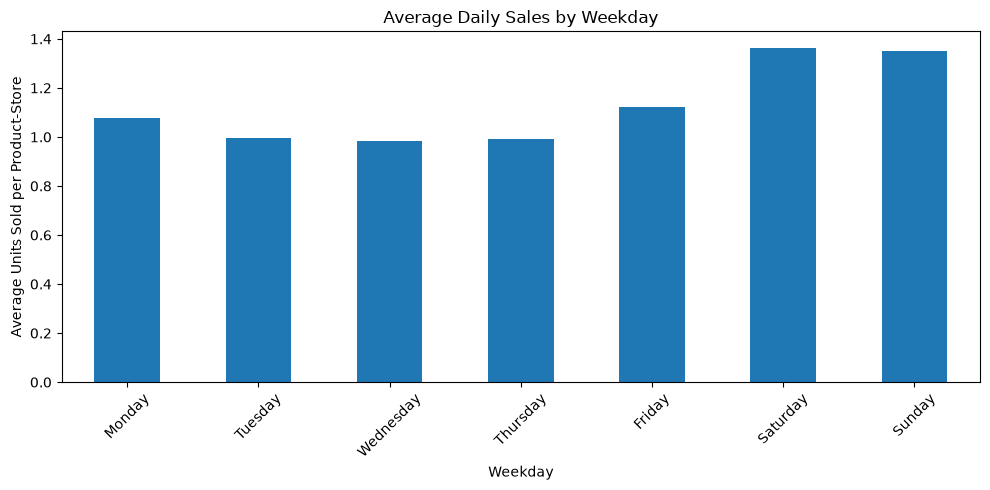

In [26]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_demand = (
    sales_long.groupby("weekday")["sales"]
    .mean()
    .reindex(weekday_order)
)

plt.figure(figsize=(10, 5))
weekday_demand.plot(kind="bar")

plt.title("Average Daily Sales by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Units Sold per Product-Store")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("AVG_SALES_WEEKDAY.png",dpi=300,bbox_inches="tight")
plt.show()

### Analyze demand by product category

In [27]:
category_demand = (
    sales_long.groupby("cat_id")["sales"]
    .mean()
    .sort_values(ascending=False)
)

print(category_demand)

cat_id
FOODS        1.640242
HOUSEHOLD    0.722981
HOBBIES      0.566668
Name: sales, dtype: float64


### Visualize category demand

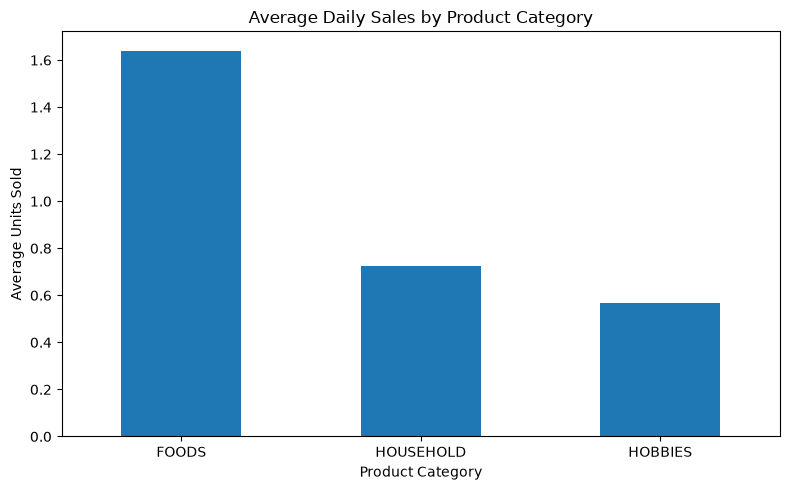

In [28]:
category_demand.plot(kind="bar", figsize=(8, 5))

plt.title("Average Daily Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [29]:
sales_long.head(1000).to_csv(
    "../data/processed/sales_sample.csv",
    index=False
)

## Checking can we use whole original dataset

# Full Dataset Preparation — Original M5 Dataset

## Objective

Extend the initial data preparation workflow to the complete M5 Forecasting Accuracy dataset while preserving the original sample-based experiments.

## Dataset Overview

* **Source:** M5 Forecasting Accuracy dataset
* **Total item-store series:** 30,490
* **Unique products:** 3,049
* **Unique stores:** 10
* **Daily sales observations:** 59,181,090
* **Total units sold:** 66,927,173
* **Sales date range:** January 29, 2011 – May 22, 2016

## Data Sources

The full-dataset workflow incorporates three primary files:

1. `sales_train_evaluation.csv` — Daily sales for each item-store series.
2. `calendar.csv` — Dates, weekly identifiers, calendar attributes, events, and SNAP indicators.
3. `sell_prices.csv` — Weekly selling prices by item and store.

## Data Preparation Workflow

### 1. Dataset Inspection

Inspected the sales dataset structure, identifier columns, daily sales columns, calendar records, and weekly price information.

### 2. Chunk-Based Processing

Processed the original sales dataset in batches and saved the transformed data as Parquet files to reduce memory pressure.

### 3. Calendar Integration

Joined calendar information with daily sales using the `d` identifier, adding date and calendar attributes to each observation.

### 4. Selling Price Integration

Joined weekly selling prices using `store_id`, `item_id`, and `wm_yr_wk`.

### 5. Missing Price Analysis

* Total records: 59,181,090
* Records with available prices: 46,881,677
* Records with missing prices: 12,299,413
* Missing-price rate: 20.78%

All records with missing prices had zero observed sales in the analysis. Missing prices were retained as null values rather than replaced with zero.

### 6. Revenue Calculation

Calculated revenue as:

`Revenue = Sales × Sell Price`

Revenue remains missing where the selling price is unavailable. The sum of revenue across records with known prices was 191,577,552.00 in the dataset's price units.

### 7. Data Quality Validation

Validated record counts, missing prices, missing revenue, total units sold, and the successful processing of all 31 Parquet files.

## Output Structure

The processed files are stored under:

`Data/processed/full_dataset/`

* `sales_chunk_*.parquet` — Chunked sales data.
* `calendar_joined/` — Sales data enriched with calendar information.
* `priced/` — Sales data enriched with weekly selling prices.
* `revenue/` — Price-enriched sales data with calculated revenue.

The full-dataset quality report is saved as:

`reports/full_dataset_quality_report.csv`

## Outcome

The original M5 dataset has been processed in manageable batches, enriched with calendar and price information, and prepared for subsequent feature engineering and demand forecasting.

## Next Steps

1. Apply the existing feature-engineering logic to all 30,490 item-store series.
2. Add suitable price-related features.
3. Validate feature completeness and prevent data leakage.
4. Train and evaluate forecasting models on the full dataset.


In [30]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = (
    PROJECT_ROOT
    / "Data"
    / "raw"
    / "m5-forecasting-accuracy"
)

sales_path = DATA_DIR / "sales_train_evaluation.csv"

print("File exists:", sales_path.exists())
print("File size (MB):", round(sales_path.stat().st_size / (1024**2), 2))

sales_sample = pd.read_csv(sales_path, nrows=5)

print("\nColumns:", sales_sample.shape[1])
print("\nSample:")
display(sales_sample.head())

File exists: True
File size (MB): 116.1

Columns: 1947

Sample:


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,2,0,0,0,2,3,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,1,0,4,0,1,3,0,2,6
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,2,1,0,0,2,1,0


### Inspect the dataset structure

In [32]:
# Separate product/store identifiers from daily sales columns
id_columns = sales_sample.columns[:6].tolist()
sales_columns = sales_sample.columns[6:].tolist()

print("Identifier columns:", id_columns)
print("Number of daily sales columns:", len(sales_columns))
print("First sales column:", sales_columns[0])
print("Last sales column:", sales_columns[-1])

# Check product and store coverage in the full dataset
sales_metadata = pd.read_csv(sales_path, usecols=id_columns)

print("\nTotal item-store series:", len(sales_metadata))
print("Unique products:", sales_metadata["item_id"].nunique())
print("Unique stores:", sales_metadata["store_id"].nunique())
print("\nDepartment distribution:")
print(sales_metadata["dept_id"].value_counts())

Identifier columns: ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']
Number of daily sales columns: 1941
First sales column: d_1
Last sales column: d_1941

Total item-store series: 30490
Unique products: 3049
Unique stores: 10

Department distribution:
dept_id
FOODS_3        8230
HOUSEHOLD_1    5320
HOUSEHOLD_2    5150
HOBBIES_1      4160
FOODS_2        3980
FOODS_1        2160
HOBBIES_2      1490
Name: count, dtype: int64


### Check the original dataset time range

In [33]:
# Inspect the date mapping file
calendar_path = DATA_DIR / "calendar.csv"

calendar = pd.read_csv(calendar_path)

print("Calendar shape:", calendar.shape)
print("\nColumns:", calendar.columns.tolist())
print("\nFirst 5 rows:")
display(calendar.head())

print("\nLast 5 rows:")
display(calendar.tail())

Calendar shape: (1969, 14)

Columns: ['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']

First 5 rows:


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1



Last 5 rows:


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
1964,2016-06-15,11620,Wednesday,5,6,2016,d_1965,NaN,NaN,NaN,NaN,0,1,1
1965,2016-06-16,11620,Thursday,6,6,2016,d_1966,NaN,NaN,NaN,NaN,0,0,0
1966,2016-06-17,11620,Friday,7,6,2016,d_1967,NaN,NaN,NaN,NaN,0,0,0
1967,2016-06-18,11621,Saturday,1,6,2016,d_1968,NaN,NaN,NaN,NaN,0,0,0
1968,2016-06-19,11621,Sunday,2,6,2016,d_1969,NBAFinalsEnd,Sporting,Father's day,Cultural,0,0,0


### Validate Date Mapping

In [34]:
# Check whether every sales day has a matching calendar date
sales_days = sales_columns
calendar_days = calendar["d"].tolist()

print("Sales day columns:", len(sales_days))
print("Calendar day records:", len(calendar_days))

missing_days = set(sales_days) - set(calendar_days)

print("Sales days missing from calendar:", len(missing_days))

# Show the mapping for the first and last sales days
calendar_lookup = calendar.set_index("d")["date"]

print("\nFirst sales day:", sales_days[0], "→", calendar_lookup.get(sales_days[0]))
print("Last sales day:", sales_days[-1], "→", calendar_lookup.get(sales_days[-1]))

Sales day columns: 1941
Calendar day records: 1969
Sales days missing from calendar: 0

First sales day: d_1 → 2011-01-29
Last sales day: d_1941 → 2016-05-22


### Analyze the full dataset structure

In [35]:
import numpy as np

batch_size = 1000

total_observations = 0
zero_sales = 0
positive_sales = 0
total_units_sold = 0

for start in range(0, len(sales_metadata), batch_size):
    batch = pd.read_csv(
        sales_path,
        skiprows=range(1, start + 1),
        nrows=batch_size,
        usecols=sales_columns
    )

    values = batch.to_numpy(dtype=np.int32)

    total_observations += values.size
    zero_sales += np.count_nonzero(values == 0)
    positive_sales += np.count_nonzero(values > 0)
    total_units_sold += values.sum(dtype=np.int64)

print(f"Total item-store series: {len(sales_metadata):,}")
print(f"Total daily observations: {total_observations:,}")
print(f"Zero-sales observations: {zero_sales:,} ({zero_sales / total_observations:.2%})")
print(f"Positive-sales observations: {positive_sales:,} ({positive_sales / total_observations:.2%})")
print(f"Total units sold across all observations: {total_units_sold:,}")

Total item-store series: 30,490
Total daily observations: 59,181,090
Zero-sales observations: 40,241,819 (68.00%)
Positive-sales observations: 18,939,271 (32.00%)
Total units sold across all observations: 66,927,173


### Save the full dataset summary to a CSV file

In [36]:
from pathlib import Path
import pandas as pd

reports_dir = PROJECT_ROOT / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

summary = pd.DataFrame([{
    "item_store_series": len(sales_metadata),
    "daily_observations": total_observations,
    "zero_sales_observations": zero_sales,
    "zero_sales_pct": round(zero_sales / total_observations * 100, 2),
    "positive_sales_observations": positive_sales,
    "positive_sales_pct": round(positive_sales / total_observations * 100, 2),
    "total_units_sold": total_units_sold
}])

output_path = reports_dir / "full_dataset_summary.csv"
summary.to_csv(output_path, index=False)

print(f"Saved: {output_path}")
display(summary)

Saved: c:\Users\lenovo\OneDrive\Desktop\Retail-demand-Forecasting\reports\full_dataset_summary.csv


,item_store_series,daily_observations,zero_sales_observations,zero_sales_pct,positive_sales_observations,positive_sales_pct,total_units_sold
0,30490,59181090,40241819,68.0,18939271,32.0,66927173


### Prepare the full dataset efficiently

###### We'll process all 30,490 item-store series in chunks to avoid memory issues.

In [37]:
from pathlib import Path
import pandas as pd

# Output directory for chunked data
processed_dir = PROJECT_ROOT / "Data" / "processed" / "full_dataset"
processed_dir.mkdir(parents=True, exist_ok=True)

# Read the complete dataset sequentially
chunk_size = 1000
chunk_number = 0

for chunk in pd.read_csv(sales_path, chunksize=chunk_size):
    id_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
    sales_cols = [col for col in chunk.columns if col.startswith("d_")]

    long_chunk = chunk.melt(
        id_vars=id_cols,
        value_vars=sales_cols,
        var_name="d",
        value_name="sales"
    )

    long_chunk["sales"] = long_chunk["sales"].astype("int16")

    output_path = processed_dir / f"sales_chunk_{chunk_number:03d}.parquet"
    long_chunk.to_parquet(output_path, index=False)

    chunk_number += 1

    if chunk_number % 5 == 0:
        print(f"Processed {chunk_number * chunk_size:,} series")

print(f"\nCompleted! Saved {chunk_number} Parquet files.")
print(f"Output folder: {processed_dir}")

Processed 5,000 series
Processed 10,000 series
Processed 15,000 series
Processed 20,000 series
Processed 25,000 series
Processed 30,000 series

Completed! Saved 31 Parquet files.
Output folder: c:\Users\lenovo\OneDrive\Desktop\Retail-demand-Forecasting\Data\processed\full_dataset


### Connect sales data with calendar 

In [38]:
from pathlib import Path
import pandas as pd

processed_dir = PROJECT_ROOT / "Data" / "processed" / "full_dataset"
calendar_path = DATA_DIR / "calendar.csv"

calendar = pd.read_csv(calendar_path)

calendar["date"] = pd.to_datetime(calendar["date"])
calendar = calendar[
    ["d", "date", "weekday", "month", "year",
     "event_name_1", "event_type_1", "snap_CA", "snap_TX", "snap_WI"]
]

output_dir = processed_dir / "calendar_joined"
output_dir.mkdir(parents=True, exist_ok=True)

parquet_files = sorted(processed_dir.glob("sales_chunk_*.parquet"))

for i, file_path in enumerate(parquet_files, start=1):
    sales = pd.read_parquet(file_path)

    merged = sales.merge(calendar, on="d", how="left", validate="many_to_one")

    merged.to_parquet(output_dir / file_path.name, index=False)

    if i % 5 == 0 or i == len(parquet_files):
        print(f"Joined calendar: {i}/{len(parquet_files)} files")

print(f"\nCompleted! Calendar-joined data saved to: {output_dir}")

Joined calendar: 5/31 files
Joined calendar: 10/31 files
Joined calendar: 15/31 files
Joined calendar: 20/31 files
Joined calendar: 25/31 files
Joined calendar: 30/31 files
Joined calendar: 31/31 files

Completed! Calendar-joined data saved to: c:\Users\lenovo\OneDrive\Desktop\Retail-demand-Forecasting\Data\processed\full_dataset\calendar_joined


### Inspect the price data

In [39]:
sell_prices_path = DATA_DIR / "sell_prices.csv"

prices_sample = pd.read_csv(sell_prices_path, nrows=5)

print("Price dataset shape (first 5 rows):", prices_sample.shape)
print("\nColumns:", prices_sample.columns.tolist())
display(prices_sample)

print("\nPrice data types:")
print(prices_sample.dtypes)

Price dataset shape (first 5 rows): (5, 4)

Columns: ['store_id', 'item_id', 'wm_yr_wk', 'sell_price']


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26



Price data types:
store_id          str
item_id           str
wm_yr_wk        int64
sell_price    float64
dtype: object


### Add the weekly price key to the calendar 

In [40]:
# Prepare the calendar-to-price mapping
calendar_price = pd.read_csv(
    calendar_path,
    usecols=["d", "wm_yr_wk"]
)

print("Calendar rows:", len(calendar_price))
print("Unique day IDs:", calendar_price["d"].nunique())
print("Unique week IDs:", calendar_price["wm_yr_wk"].nunique())
print("\nSample:")
display(calendar_price.head())

Calendar rows: 1969
Unique day IDs: 1969
Unique week IDs: 282

Sample:


,wm_yr_wk,d
0,11101,d_1
1,11101,d_2
2,11101,d_3
3,11101,d_4
4,11101,d_5


### Add wm_yr_wk and selling prices

In [41]:
import pandas as pd

# Load the calendar-to-week mapping and weekly prices
calendar_price = pd.read_csv(
    calendar_path,
    usecols=["d", "wm_yr_wk"]
)

sell_prices = pd.read_csv(
    sell_prices_path,
    dtype={
        "store_id": "category",
        "item_id": "category",
        "wm_yr_wk": "int32",
        "sell_price": "float32"
    }
)

# Prepare output folder
priced_dir = processed_dir / "priced"
priced_dir.mkdir(parents=True, exist_ok=True)

parquet_files = sorted(
    (processed_dir / "calendar_joined").glob("sales_chunk_*.parquet")
)

for i, file_path in enumerate(parquet_files, start=1):
    sales = pd.read_parquet(file_path)

    # Add week ID using day ID
    sales = sales.merge(
        calendar_price,
        on="d",
        how="left",
        validate="many_to_one"
    )

    # Match product, store and week to the selling price
    sales = sales.merge(
        sell_prices,
        on=["store_id", "item_id", "wm_yr_wk"],
        how="left",
        validate="many_to_one"
    )

    sales.to_parquet(priced_dir / file_path.name, index=False)

    if i % 5 == 0 or i == len(parquet_files):
        print(f"Price join complete: {i}/{len(parquet_files)} files")

print(f"\nCompleted! Price-enriched files saved to: {priced_dir}")

Price join complete: 5/31 files
Price join complete: 10/31 files
Price join complete: 15/31 files
Price join complete: 20/31 files
Price join complete: 25/31 files
Price join complete: 30/31 files
Price join complete: 31/31 files

Completed! Price-enriched files saved to: c:\Users\lenovo\OneDrive\Desktop\Retail-demand-Forecasting\Data\processed\full_dataset\priced


### Validate the price join      

In [42]:
import pandas as pd

priced_dir = processed_dir / "priced"
parquet_files = sorted(priced_dir.glob("sales_chunk_*.parquet"))

total_rows = 0
missing_prices = 0
total_sales = 0
priced_rows = 0

for i, file_path in enumerate(parquet_files, start=1):
    df = pd.read_parquet(file_path)

    total_rows += len(df)
    missing_prices += df["sell_price"].isna().sum()
    priced_rows += df["sell_price"].notna().sum()
    total_sales += df["sales"].sum()

    if i % 10 == 0 or i == len(parquet_files):
        print(f"Validated {i}/{len(parquet_files)} files")

price_quality = pd.DataFrame([{
    "total_records": total_rows,
    "records_with_price": priced_rows,
    "records_missing_price": missing_prices,
    "missing_price_pct": round(missing_prices / total_rows * 100, 2),
    "total_units_sold": int(total_sales)
}])

display(price_quality)

Validated 10/31 files
Validated 20/31 files
Validated 30/31 files
Validated 31/31 files


,total_records,records_with_price,records_missing_price,missing_price_pct,total_units_sold
0,59181090,46881677,12299413,20.78,66927173


### Investigate the missing prices 

In [43]:
import pandas as pd

priced_dir = processed_dir / "priced"
parquet_files = sorted(priced_dir.glob("sales_chunk_*.parquet"))

missing_price_zero_sales = 0
missing_price_positive_sales = 0
available_price_zero_sales = 0
available_price_positive_sales = 0

for i, file_path in enumerate(parquet_files, start=1):
    df = pd.read_parquet(
        file_path,
        columns=["sales", "sell_price"]
    )

    missing = df["sell_price"].isna()
    zero_sales = df["sales"].eq(0)
    positive_sales = df["sales"].gt(0)

    missing_price_zero_sales += int((missing & zero_sales).sum())
    missing_price_positive_sales += int((missing & positive_sales).sum())
    available_price_zero_sales += int((~missing & zero_sales).sum())
    available_price_positive_sales += int((~missing & positive_sales).sum())

    if i % 10 == 0 or i == len(parquet_files):
        print(f"Analyzed {i}/{len(parquet_files)} files")

missing_price_analysis = pd.DataFrame([
    {
        "category": "Missing price",
        "zero_sales_records": missing_price_zero_sales,
        "positive_sales_records": missing_price_positive_sales
    },
    {
        "category": "Price available",
        "zero_sales_records": available_price_zero_sales,
        "positive_sales_records": available_price_positive_sales
    }
])

display(missing_price_analysis)

Analyzed 10/31 files
Analyzed 20/31 files
Analyzed 30/31 files
Analyzed 31/31 files


,category,zero_sales_records,positive_sales_records
0,Missing price,12299413,0
1,Price available,27942406,18939271


### ADD REVENUE 

In [44]:
import pandas as pd

priced_dir = processed_dir / "priced"
revenue_dir = processed_dir / "revenue"
revenue_dir.mkdir(parents=True, exist_ok=True)

parquet_files = sorted(priced_dir.glob("sales_chunk_*.parquet"))

for i, file_path in enumerate(parquet_files, start=1):
    df = pd.read_parquet(file_path)

    # Calculate revenue only where a price is available
    df["revenue"] = df["sales"] * df["sell_price"]

    df.to_parquet(revenue_dir / file_path.name, index=False)

    if i % 5 == 0 or i == len(parquet_files):
        print(f"Revenue calculated: {i}/{len(parquet_files)} files")

print(f"\nRevenue data saved to: {revenue_dir}")

Revenue calculated: 5/31 files
Revenue calculated: 10/31 files
Revenue calculated: 15/31 files
Revenue calculated: 20/31 files
Revenue calculated: 25/31 files
Revenue calculated: 30/31 files
Revenue calculated: 31/31 files

Revenue data saved to: c:\Users\lenovo\OneDrive\Desktop\Retail-demand-Forecasting\Data\processed\full_dataset\revenue


### Validate revenue and save the final quality report

In [45]:
import pandas as pd

revenue_dir = processed_dir / "revenue"
parquet_files = sorted(revenue_dir.glob("sales_chunk_*.parquet"))

total_rows = 0
total_revenue = 0.0
missing_prices = 0
missing_revenue = 0

for i, file_path in enumerate(parquet_files, start=1):
    df = pd.read_parquet(
        file_path,
        columns=["sales", "sell_price", "revenue"]
    )

    total_rows += len(df)
    missing_prices += int(df["sell_price"].isna().sum())
    missing_revenue += int(df["revenue"].isna().sum())
    total_revenue += df["revenue"].sum()

    if i % 10 == 0 or i == len(parquet_files):
        print(f"Validated {i}/{len(parquet_files)} files")

report = pd.DataFrame([{
    "total_records": total_rows,
    "total_units_sold": 66927173,
    "records_missing_prices": missing_prices,
    "records_missing_revenue": missing_revenue,
    "total_revenue_known_prices": round(total_revenue, 2),
    "files_processed": len(parquet_files)
}])

display(report)

report_path = PROJECT_ROOT / "reports" / "full_dataset_quality_report.csv"
report_path.parent.mkdir(parents=True, exist_ok=True)
report.to_csv(report_path, index=False)

print(f"\nReport saved to: {report_path}")

Validated 10/31 files
Validated 20/31 files
Validated 30/31 files
Validated 31/31 files


,total_records,total_units_sold,records_missing_prices,records_missing_revenue,total_revenue_known_prices,files_processed
0,59181090,66927173,12299413,12299413,191577552.0,31



Report saved to: c:\Users\lenovo\OneDrive\Desktop\Retail-demand-Forecasting\reports\full_dataset_quality_report.csv
